In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('ggplot')

In [2]:
# Q1 - chargement
data = pd.read_csv('prix_maisons.csv')
data.head()

,prix,surface,nb_chambres,age,dist_centre,garage
0,234.2,110,2,26,13.9,1
1,262.6,120,4,49,5.4,1
2,250.3,101,3,6,8.3,0
3,181.4,82,3,17,17.8,0
4,183.5,95,4,35,19.4,1


In [3]:
print('Taille du dataset :', data.shape)
print()
print(data.dtypes)

Taille du dataset : (200, 6)

prix           float64
surface          int64
nb_chambres      int64
age              int64
dist_centre    float64
garage           int64
dtype: object


In [4]:
data.describe()

,prix,surface,nb_chambres,age,dist_centre,garage
count,200.000000,200.00000,200.00000,200.00000,200.000000,200.000000
mean,229.927000,105.80000,3.00000,30.62500,12.274000,0.600000
std,63.972243,27.84541,1.08438,16.74804,6.923184,0.491127
min,43.700000,40.00000,1.00000,0.00000,0.600000,0.000000
25%,192.175000,89.00000,2.00000,17.00000,6.500000,0.000000
50%,229.800000,105.50000,3.00000,30.00000,12.050000,1.000000
75%,272.450000,126.00000,4.00000,46.00000,18.325000,1.000000
max,359.300000,182.00000,6.00000,60.00000,24.800000,1.000000


In [5]:
data.isna().sum()

prix           0
surface        0
nb_chambres    0
age            0
dist_centre    0
garage         0
dtype: int64

In [6]:
# Q2 - X et y
features = ['surface', 'nb_chambres', 'age', 'dist_centre', 'garage']
X = data[features]
y = data['prix']
print('X :', X.shape, ' | y :', y.shape)

X : (200, 5)  | y : (200,)


In [7]:
# Q3 - split 80/20 + standardisation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

print('train :', X_train_s.shape, ' test :', X_test_s.shape)
print('moyennes apprises :', sc.mean_.round(2))

train : (160, 5)  test : (40, 5)
moyennes apprises : [106.12   2.99  30.34  12.31   0.57]


In [8]:
# Q4 - LinearRegression
lr = LinearRegression()
lr.fit(X_train_s, y_train)
print('intercept_ :', round(lr.intercept_, 4))
for nom, c in zip(features, lr.coef_):
    print(f'  {nom:<12} {c:9.4f}')

intercept_ : 230.3888
  surface        48.3283
  nb_chambres     8.7257
  age           -17.9116
  dist_centre   -25.3541
  garage         10.4878


In [9]:
# Q5 - prediction + metriques
y_pred_lr = lr.predict(X_test_s)
print(pd.DataFrame({'reel': y_test.values[:5], 'predit': y_pred_lr[:5].round(2)}))

mae_lr  = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr   = r2_score(y_test, y_pred_lr)
print(f'\nMAE = {mae_lr:.3f}   RMSE = {rmse_lr:.3f}   R2 = {r2_lr:.4f}')

    reel  predit
0  268.8  271.12
1  300.4  298.74
2  182.7  170.25
3  349.9  353.03
4  103.7  113.80

MAE = 11.596   RMSE = 14.158   R2 = 0.9489


In [10]:
# Q6 - SGDRegressor
sgd = SGDRegressor(loss='squared_error', penalty=None, learning_rate='constant',
                   eta0=0.01, max_iter=2000, tol=None, random_state=42)
sgd.fit(X_train_s, y_train)
print('intercept_ :', sgd.intercept_)
for nom, c in zip(features, sgd.coef_):
    print(f'  {nom:<12} {c:9.4f}')
print('n_iter_ :', sgd.n_iter_)

intercept_ : [230.836422]
  surface        48.4497
  nb_chambres     8.5430
  age           -17.7952
  dist_centre   -25.9609
  garage         11.2687
n_iter_ : 2000


In [11]:
# Q7
y_pred_sgd = sgd.predict(X_test_s)
mae_sgd  = mean_absolute_error(y_test, y_pred_sgd)
rmse_sgd = np.sqrt(mean_squared_error(y_test, y_pred_sgd))
r2_sgd   = r2_score(y_test, y_pred_sgd)
print(f'MAE = {mae_sgd:.3f}   RMSE = {rmse_sgd:.3f}   R2 = {r2_sgd:.4f}')

MAE = 12.091   RMSE = 14.571   R2 = 0.9459


In [12]:
# Q8 - tableau comparatif
res = pd.DataFrame({'MAE': [mae_lr, mae_sgd],
                    'RMSE': [rmse_lr, rmse_sgd],
                    'R2': [r2_lr, r2_sgd]},
                   index=['LinearRegression', 'SGDRegressor'])
res.round(4)

,MAE,RMSE,R2
LinearRegression,11.5957,14.1579,0.9489
SGDRegressor,12.0906,14.5710,0.9459


In [13]:
# ecart entre les coefficients des deux modeles
pd.DataFrame({'LR': lr.coef_, 'SGD': sgd.coef_, 'ecart': lr.coef_ - sgd.coef_}, index=features).round(3)

,LR,SGD,ecart
surface,48.328,48.450,-0.121
nb_chambres,8.726,8.543,0.183
age,-17.912,-17.795,-0.116
dist_centre,-25.354,-25.961,0.607
garage,10.488,11.269,-0.781


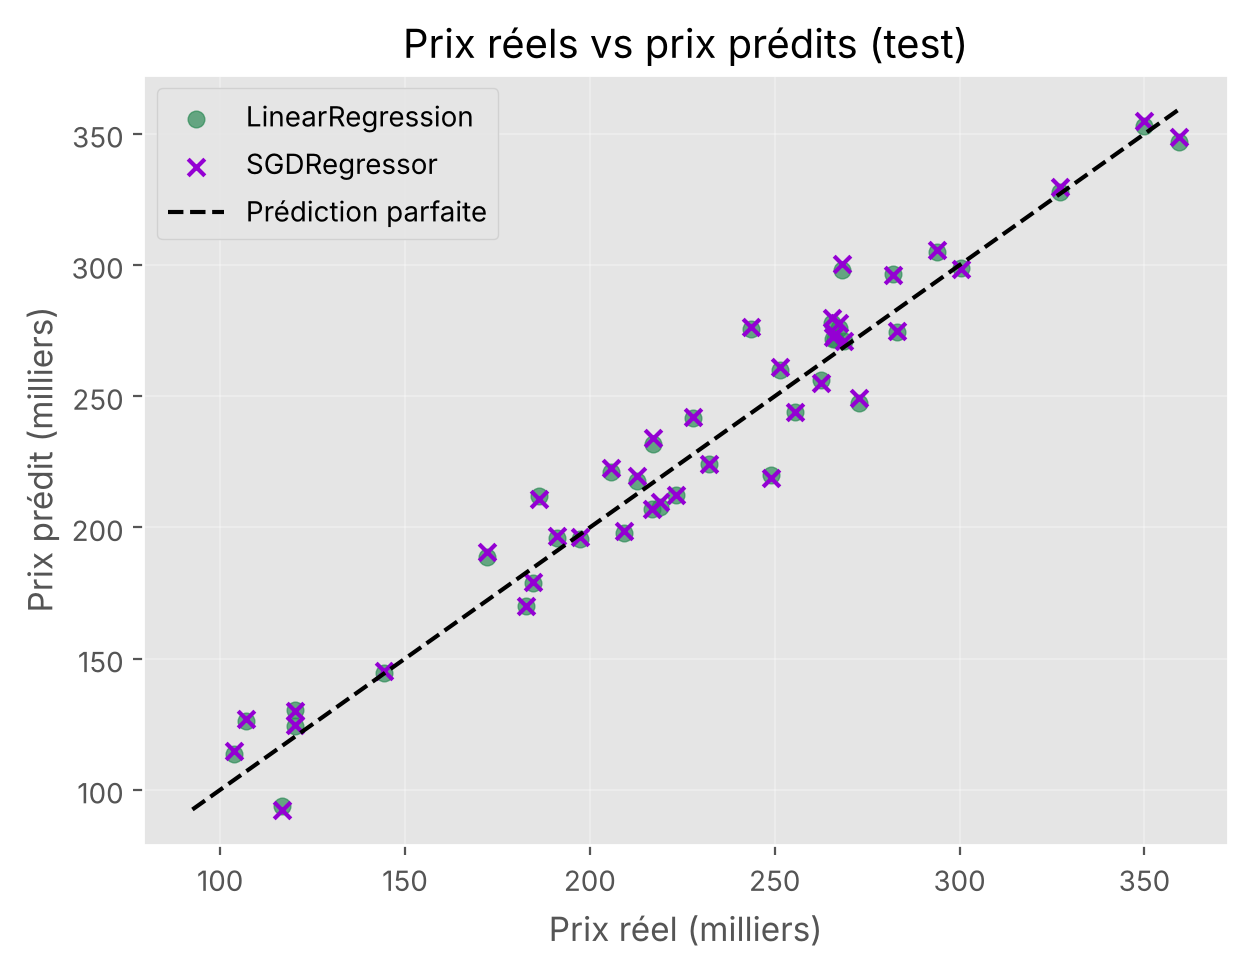

In [14]:
# Q9 - reel vs predit
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_lr, alpha=0.7, color='seagreen', label='LinearRegression')
plt.scatter(y_test, y_pred_sgd, marker='x', color='darkviolet', label='SGDRegressor')
m = min(y_test.min(), y_pred_lr.min(), y_pred_sgd.min())
M = max(y_test.max(), y_pred_lr.max(), y_pred_sgd.max())
plt.plot([m, M], [m, M], 'k--', label='Prédiction parfaite')
plt.xlabel("Prix réel (milliers)")
plt.ylabel("Prix prédit (milliers)")
plt.title("Prix réels vs prix prédits (test)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
# Q10 - influence de eta0
lignes = []
for eta in [0.0001, 0.001, 0.01]:
    m_eta = SGDRegressor(loss='squared_error', penalty=None, learning_rate='constant',
                         eta0=eta, max_iter=2000, tol=None, random_state=42)
    m_eta.fit(X_train_s, y_train)
    p = m_eta.predict(X_test_s)
    lignes.append([eta, mean_absolute_error(y_test, p),
                   np.sqrt(mean_squared_error(y_test, p)), r2_score(y_test, p)])
pd.DataFrame(lignes, columns=['eta0', 'MAE', 'RMSE', 'R2']).round(4)

,eta0,MAE,RMSE,R2
0,0.0001,11.5964,14.1589,0.9489
1,0.0010,11.6138,14.1744,0.9488
2,0.0100,12.0906,14.5710,0.9459


In [16]:
# Q11 - sans standardisation, eta0 = 0.01
sgd_brut = SGDRegressor(loss='squared_error', penalty=None, learning_rate='constant',
                        eta0=0.01, max_iter=2000, tol=None, random_state=42)
sgd_brut.fit(X_train, y_train)
p_brut = sgd_brut.predict(X_test)
print('RMSE sans standardisation :', np.sqrt(mean_squared_error(y_test, p_brut)))

RMSE sans standardisation : 30492401757958.508


In [17]:
# on reessaie avec un pas beaucoup plus petit
sgd_brut2 = SGDRegressor(loss='squared_error', penalty=None, learning_rate='constant',
                         eta0=0.00001, max_iter=2000, tol=None, random_state=42)
sgd_brut2.fit(X_train, y_train)
p_brut2 = sgd_brut2.predict(X_test)
print('eta0 = 1e-5  ->  RMSE =', round(np.sqrt(mean_squared_error(y_test, p_brut2)), 3),
      ' R2 =', round(r2_score(y_test, p_brut2), 4))

eta0 = 1e-5  ->  RMSE = 23.401  R2 = 0.8605


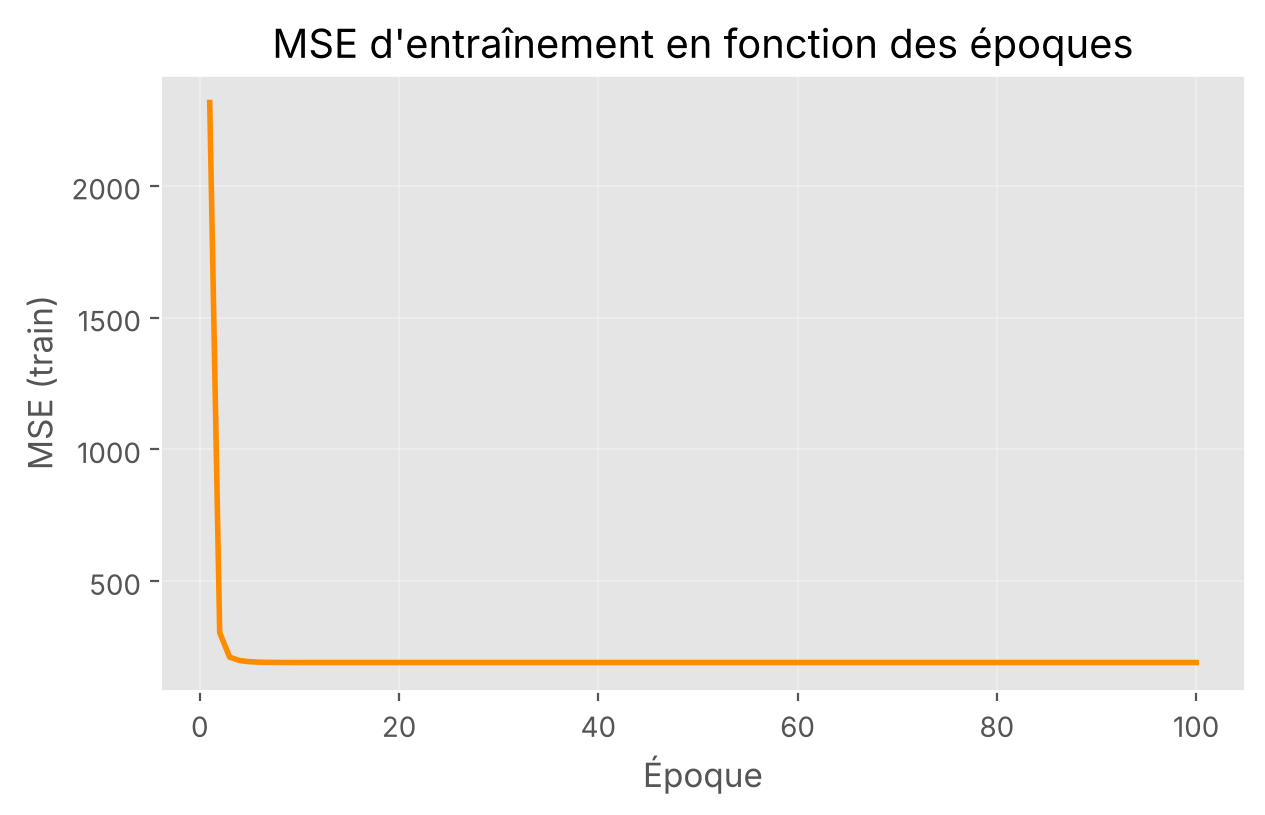

min = 191.86  max = 2316.32  derniere = 191.86


In [18]:
# Q12 - suivi de la MSE avec partial_fit
suivi = SGDRegressor(loss='squared_error', penalty=None, learning_rate='constant',
                     eta0=0.01, random_state=42)
mse = []
for ep in range(100):
    suivi.partial_fit(X_train_s, y_train)
    mse.append(mean_squared_error(y_train, suivi.predict(X_train_s)))

plt.figure(figsize=(7, 4))
plt.plot(range(1, 101), mse, color='darkorange', linewidth=2)
plt.xlabel("Époque")
plt.ylabel("MSE (train)")
plt.title("MSE d'entraînement en fonction des époques")
plt.grid(alpha=0.3)
plt.show()
print('min =', round(min(mse), 2), ' max =', round(max(mse), 2), ' derniere =', round(mse[-1], 2))

In [19]:
# Q13 - nouvelle maison
maison = pd.DataFrame([[125, 3, 15, 7.5, 1]], columns=features)
maison_s = sc.transform(maison)
print('LinearRegression :', round(lr.predict(maison_s)[0], 2), 'milliers')
print('SGDRegressor     :', round(sgd.predict(maison_s)[0], 2), 'milliers')

LinearRegression : 307.64 milliers
SGDRegressor     : 309.18 milliers
